# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 4b: Baseline - Skema 2 "Tokenizer"
Tokenizer subword IndoBERT -> embedding layer IndoBERT 768-dim (frozen) -> mean pooling -> Logistic Regression

Hanya tokenizer dan tabel embedding token IndoBERT yang dipakai (encoder transformer tidak dipakai, tidak ada fine-tuning). Yang dilatih hanya Logistic Regression.

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`, `utils_embedding.py`
- Output: `outputs/baseline_tokenizer_val_results.json`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [ ]:
import os, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                            classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Skema 2 (tokenizer subword + embedding frozen IndoBERT); utils_embedding.py
from utils_embedding import (MODEL_NAME, PRETRAINED_DIM, get_device, load_tokenizer_and_frozen_embedding,
                            encode_subword, mean_pool_embeddings)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
RESULT_PATH = "outputs/baseline_tokenizer_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42
MAX_LEN = 128 # dalam token subword;

os.makedirs(FIG_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
y_train, y_val = train_df[LABEL_COL], val_df[LABEL_COL]
device = get_device()
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels, "| Device:", device)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad'] | Device: cpu


### Step 2 - Tokenizer subword IndoBERT & embedding layer frozen

In [ ]:
tokenizer, emb_layer = load_tokenizer_and_frozen_embedding(MODEL_NAME)
PAD_ID = tokenizer.pad_token_id
print(f"Checkpoint: {MODEL_NAME} | vocab subword: {tokenizer.vocab_size} | embedding: {tuple(emb_layer.weight.shape)}")
print("Embedding beku (requires_grad):", emb_layer.weight.requires_grad)
assert not emb_layer.weight.requires_grad

contoh = train_df[TEXT_COL].iloc[0]
print("\nContoh teks:", contoh[:80])
print("Subword:", tokenizer.tokenize(contoh)[:12])

ids_train, M_train = encode_subword(train_df[TEXT_COL].tolist(), tokenizer, MAX_LEN)
ids_val, M_val = encode_subword(val_df[TEXT_COL].tolist(), tokenizer, MAX_LEN)

# Cek panjang subword asli di train dan brp banyak yg terpotong
len_full = np.array([len(x) for x in tokenizer(train_df[TEXT_COL].tolist(), add_special_tokens=False)["input_ids"]])
print(f"Panjang subword train: rata-rata {len_full.mean():.1f} | persentil 95 = {np.percentile(len_full, 95):.0f} | maks = {len_full.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {(len_full > MAX_LEN).mean()*100:.2f}%")
print("Bentuk id token -> train:", tuple(ids_train.shape), "| val:", tuple(ids_val.shape))

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Checkpoint: indobenchmark/indobert-base-p1 | vocab subword: 30521 | embedding: (50000, 768)
Embedding beku (requires_grad): False

Contoh teks: 365. kalau mau gestun limit kamu di spaylater, gopay coin, gopaylater, akulaku, 
Subword: ['365', '.', 'kalau', 'mau', 'ges', '##tu', '##n', 'limit', 'kamu', 'di', 'spa', '##yl']
Panjang subword train: rata-rata 22.5 | persentil 95 = 59 | maks = 86
Teks train yang terpotong oleh MAX_LEN=128: 0.00%
Bentuk id token -> train: (4921, 128) | val: (1055, 128)


### Step 3 - Representasi dokumen = mean pooling frozen embedding
Tiap teks -> id subword -> vektor embedding pre-trained (768-dim, beku) -> rata-rata token asli (padding diabaikan) -> 1 vektor 768-dim. Dilakukan di bawah `torch.no_grad()`; sangat cepat karena hanya pencarian tabel embedding.

In [ ]:
X_train = mean_pool_embeddings(ids_train, M_train, emb_layer, device)
X_val = mean_pool_embeddings(ids_val, M_val, emb_layer, device)

assert X_train.shape == (len(train_df), PRETRAINED_DIM) and X_val.shape == (len(val_df), PRETRAINED_DIM)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

nol_train = int((np.abs(X_train).sum(axis=1) == 0).sum())
nol_val = int((np.abs(X_val).sum(axis=1) == 0).sum())
print("Matriks fitur train:", X_train.shape, "| val:", X_val.shape)
pd.DataFrame({
    "pemeriksaan": ["Dimensi fitur", "Teks train dengan vektor nol", "Teks validation dengan vektor nol",
                    "Parameter embedding yang dilatih (requires_grad)"],
    "nilai": [X_train.shape[1], nol_train, nol_val, int(emb_layer.weight.requires_grad)],
})

Matriks fitur train: (4921, 768) | val: (1055, 768)


,pemeriksaan,nilai
0,Dimensi fitur,768
1,Teks train dengan vektor nol,0
2,Teks validation dengan vektor nol,0
3,Parameter embedding yang dilatih (requires_grad),0


### Step 4 - Logistic Regression (multiclass)

In [ ]:
# Standarisasi fitur (fit hanya pada train): langkah yang sama dengan baseline Skema 1 (04b). Bukan tuning.
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

# Logistic Regression default sklearn, tanpa tuning (setelan sama dengan 04b)
clf = LogisticRegression(max_iter=1000, random_state=SEED)
clf.fit(X_train_s, y_train)
print("Model terlatih. Kelas:", list(clf.classes_))

Model terlatih. Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 5 - Evaluasi di validation set

In [ ]:
y_pred = clf.predict(X_val_s)

acc = accuracy_score(y_val, y_pred)
macro_p = precision_score(y_val, y_pred, average="macro", zero_division=0)
macro_r = recall_score(y_val, y_pred, average="macro", zero_division=0)
macro_f1 = f1_score(y_val, y_pred, average="macro")

kelas_terbanyak = y_train.value_counts().idxmax()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {(y_val == kelas_terbanyak).mean():.4f}")
print(f"Baseline Skema 2 (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

# Satu tabel: per kelas + accuracy + macro avg + weighted avg (format sama di semua notebook)
rapor = classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val)]
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
Baseline Skema 2 (val): accuracy = 0.5924 | macro-F1 = 0.5979


,precision,recall,f1-score,support
anger,0.6038,0.5714,0.5872,168
fear,0.6752,0.5809,0.6245,136
joy,0.5806,0.5714,0.5760,189
love,0.539,0.6726,0.5984,113
neutral,0.5686,0.5705,0.5695,298
sad,0.6275,0.6358,0.6316,151
accuracy,,,0.5924,1055
macro avg,0.5991,0.6004,0.5979,1055
weighted avg,0.5953,0.5924,0.5926,1055


### Step 6 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,96,11,14,8,33,6
asli_fear,14,79,10,7,21,5
asli_joy,7,8,108,20,32,14
asli_love,6,2,10,76,14,5
asli_neutral,31,16,27,27,170,27
asli_sad,5,1,17,3,29,96


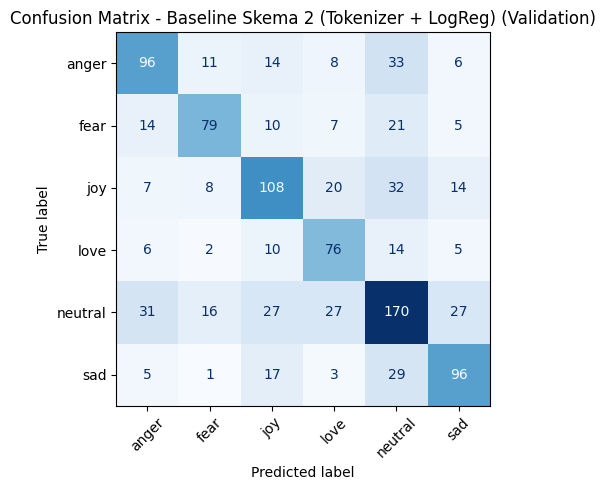

In [6]:
cm = confusion_matrix(y_val, y_pred, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Baseline Skema 2 (Tokenizer + LogReg) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04b_confusion_matrix_baseline_tokenizer_val.png", dpi=150)
plt.show()

### Step 7 - Simpan hasil

In [ ]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "Baseline (LogReg)", "feature_extraction": "tokenizer", "split": "validation",
                "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
                "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
                "extractor": f"tokenizer subword + embedding layer {MODEL_NAME} (beku) + mean pooling",
                "n_features": int(PRETRAINED_DIM), "tokenizer_vocab_size": int(tokenizer.vocab_size),
                "max_len": int(MAX_LEN)}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/baseline_tokenizer_val_results.json


### Notes Part 4b:
- Checkpoint | dimensi fitur: indobenchmark/indobert-base-p1 | 768
- Embedding dilatih? False (frozen)
- Teks train terpotong oleh MAX_LEN=128 : tidak ada (0%)
- Accuracy | Macro-F1 (validation): 0.5924 | 0.5979
- Macro-Precision | Macro-Recall: 0.5991 | 0.6004
- F1 tertinggi | terendah per kelas: sad (0.6316) | neutral (0.5695)
- Pasangan kelas yang paling sering tertukar: anger dan neutral (64 kesalahan di dua arah)
- Test set belum disentuh.